# Sesión 3 — Taller práctico

**Grupo:** 9  
**Nombre:** Mario Daniel Enrique Perez Jimenez  
**Cédula:** 1152456361  
**Código de estudiante:** 202610093727  

---

Sesión 3 — Taller práctico: ¿podemos confiar en lo que vemos? (CONECTA, proyecto A: Retención)

**Curso:** Visualización de Datos y Gerencia de la Información  
**Sesión:** 3 de 9  
**Tipo:** Notebook práctico

## Instrucciones de entrega

- Equipos de 3 personas. Entreguen este notebook **ejecutado de inicio a fin** como
  `DATAVIZ_sesion_3_proyecto_A_grupo_Y.ipynb` en el plazo acordado en clase, con los archivos que el notebook deja en
  `salidas/` (la tabla limpia y las UPZ candidatas).
- Completen las celdas `# TODO` en el orden indicado (los conteos dependen del orden) y escriban en las celdas
  **Su respuesta**.
- Pueden apoyarse en un asistente de IA para concentrarse en lo importante y en las decisiones; declaren al final
  para qué lo usaron.

## Problemática de negocio

CONECTA S.A. es un operador de telecomunicaciones en Bogotá con dos líneas, **Hogar** (internet fijo) y **Móvil**
(pospago y prepago), con datos sintéticos del curso. La Gerencia de Retención lleva al comité de diciembre una
propuesta de campaña contra las cancelaciones para el primer trimestre de 2027. En la S2 el equipo calculó una tasa
por localidad y por segmento con datos sin revisar, y vio 38 formas de escribir 19 localidades y filas con pago 0.
Antes de llevar un hallazgo al comité hay que responder: **¿qué cuenta como una cancelación y en qué datos se puede
confiar?**

Al final del taller el equipo guarda en `salidas/` la **tabla limpia** y las **10 UPZ candidatas** con las que empieza la S4. La S4 parte de la tabla limpia del curso, que es idéntica a la suya si
aplicaron bien las reglas (el solucionario lo verifica).

## Preparación del entorno

In [1]:
import pathlib

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# El notebook busca datos/ e imagenes/ en su carpeta (o en la de arriba, si está en solucionario/).
BASE = pathlib.Path(".") if pathlib.Path("datos").exists() else pathlib.Path("..")
DATOS, IMAGENES = BASE / "datos", BASE / "imagenes"
IMAGENES.mkdir(exist_ok=True)
# Lo que produce el taller se guarda en salidas/, junto al notebook que se ejecuta (el del estudiante en su carpeta;
# el del solucionario, en solucionario/salidas/): así el solucionario no deja respuestas en la carpeta del estudiante.
SALIDAS = pathlib.Path("salidas")
SALIDAS.mkdir(exist_ok=True)

PALETA = {"principal": "#0F766E", "principal_claro": "#4E9F96", "marino": "#1F2A44", "secundario": "#5B6475",
          "neutro": "#8A93A3", "fondo": "#F3F5F9", "acento": "#B85C0A", "texto": "#1F2937"}
plt.rcParams.update({
    "font.family": "Calibri", "font.size": 11, "axes.edgecolor": PALETA["secundario"],
    "axes.labelcolor": PALETA["texto"], "xtick.color": PALETA["secundario"], "ytick.color": PALETA["secundario"],
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 150, "savefig.dpi": 150,
    "savefig.bbox": "tight"})
# Con Calibri, matplotlib no dibuja bien los tamaños enteros 8 y 9 (se usan 8.5, 9.5 o más) ni el texto a 110 ppp: figure.dpi = 150.


def miles(n, redondeo=0):
    """Entero con espacio de miles; redondeo=-3 redondea a miles."""
    return f"{round(n, redondeo):,.0f}".replace(",", " ")


def decimal(x, d=1):
    return f"{x:.{d}f}".replace(".", ",")


def titulo(fig, texto, subtitulo, y=1.04):
    fig.text(0.01, y, texto, fontsize=15, fontweight="bold", color=PALETA["texto"], ha="left")
    fig.text(0.01, y - 0.055, subtitulo, fontsize=11, color=PALETA["secundario"], ha="left")


def fuente(fig, texto):
    fig.text(0.01, -0.04, texto, fontsize=8.5, color=PALETA["secundario"], ha="left")


def guardar(fig, nombre):
    """Guarda la figura en imagenes/ (la presentación usa estos archivos) y la muestra."""
    fig.savefig(IMAGENES / nombre)
    plt.show()


def limpiar_ejes(ax, x=True, y=False):
    if x:
        ax.set_xticks([]); ax.spines["bottom"].set_visible(False)
    if y:
        ax.set_yticks([])
    ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)

In [2]:
FUENTE_CONECTA = "Fuente: CONECTA S.A., datos sintéticos del curso (nov. 2025 – oct. 2026)."
crudo = pd.read_csv(DATOS / "conecta_clientes_mes.csv", dtype={"mes": str})
upz = gpd.read_file(DATOS / "upz.geojson")
print(f"{miles(len(crudo))} filas; {miles(crudo['cliente_id'].nunique())} clientes; columnas: {list(crudo.columns)}")
d = crudo.copy()   # la tabla de trabajo: cada regla de la Tarea 2 la modifica

354 693 filas; 36 601 clientes; columnas: ['cliente_id', 'mes', 'codigo_upz', 'upz', 'localidad', 'estrato', 'latitud', 'longitud', 'linea', 'modalidad', 'plan', 'fecha_alta', 'antiguedad_meses', 'ingreso_mensual_cop', 'uso_datos_gb', 'quejas_mes', 'nps', 'cancelo', 'tipo_cancelacion']


## Tarea 1 — Perfil de calidad

Hagan un perfil de cada columna: tipo, porcentaje de nulos y número de valores distintos. Compárenlo con el
diccionario de datos (`datos/diccionario_conecta.md`) y marquen las columnas que tienen más valores distintos de los
que deberían, las que tienen nulos y las que repiten información de otra columna (por ejemplo, un nombre que se
deduce de un código).

*Consulten en la presentación:* diapositiva 10, «Cuatro categorías de calidad» (sección «La calidad de los datos»).

In [3]:
perfil = pd.DataFrame({"tipo": crudo.dtypes.astype(str),
                       "nulos_pct": (100 * crudo.isna().mean()).round(2),
                       "distintos": crudo.nunique()})
display(perfil)

# ¿Repite una columna lo que dice otra? Localidad y UPZ se deducen del código de UPZ.
print("Formas de escribir la localidad por código de UPZ (máx):",
      crudo.groupby("codigo_upz")["localidad"].nunique().max())
print("Formas de escribir la UPZ por código (máx):",
      crudo.groupby("codigo_upz")["upz"].nunique().max())
print("Localidades distintas:", crudo["localidad"].nunique(), "(oficiales:", upz["localidad"].nunique(), ")")
print("Planes distintos:", sorted(crudo["plan"].unique()))


,tipo,nulos_pct,distintos
cliente_id,object,0.00,36601
mes,object,0.00,12
codigo_upz,int64,0.00,102
upz,object,0.00,102
localidad,object,0.00,38
estrato,int64,0.00,6
latitud,float64,1.50,34944
longitud,float64,1.50,33769
linea,object,0.00,2
modalidad,object,0.00,2


Formas de escribir la localidad por código de UPZ (máx): 2
Formas de escribir la UPZ por código (máx): 1
Localidades distintas: 38 (oficiales: 19 )
Planes distintos: ['Basico', 'Básico', 'Estándar', 'PLUS', 'Plus', 'estandar']


**Clasifiquen los problemas del perfil en las categorías de Wang y Strong (1996) y digan qué columnas repiten información de otra.**

*Consulten en la presentación:* diapositiva 9, «La calidad de un dato es su aptitud para el uso» (sección «La calidad de los datos»); diapositiva 10, «Cuatro categorías de calidad» (sección «La calidad de los datos»).

**Su respuesta:**

- `localidad`: **38 grafías para 19 localidades oficiales** (hasta 2 nombres por código de UPZ) — representacional (inconsistencia de representación). El nombre correcto se deduce de `codigo_upz`.
- `plan`: **6 grafías para 3 planes** (con y sin tilde, mayúsculas) — representacional.
- `latitud` y `longitud`: **1 039 filas intercambiadas** (latitud cerca de −74) y **1,5 % de nulas** (5 264 en la tabla limpia, impreso en la celda de la Tarea 2) — intrínseca (exactitud) para las cambiadas; completitud para las nulas.
- `nps`: **78,5 % de nulos** — contextual (completitud); además la falta no es al azar (Tarea 4).
- `ingreso_mensual_cop`: filas en **0 COP** que resultan ser cuentas internas y de prueba, no clientes — contextual (relevancia: no pertenecen a la pregunta).
- `tipo_cancelacion`: vacío cuando `cancelo` = 0 (96,9 %) — no es un faltante sino la estructura del sistema; representacional.
- Filas **duplicadas exactas**: 1 765 — intrínseca (exactitud): duplican clientes-mes.
- **Columnas que repiten información:** `localidad` y `upz` se deducen de `codigo_upz`; `antiguedad_meses` se deduce de `fecha_alta` y `mes`; el `estrato` acompaña a la dirección registrada.


## Tarea 2 — Reglas de limpieza

Apliquen las reglas en este orden:

1. Eliminen las filas duplicadas exactas, la cuenta de prueba `CNX-PRUEBA-01` y las cuentas con pago 0 en **todos**
   los meses (empleados y pruebas).
2. Nombres de localidad y de plan: la celda ya está hecha; ejecútenla y lean qué hace.
3. Coordenadas: hay filas con latitud y longitud intercambiadas (latitud cerca de −74) y filas sin coordenadas.
   Corrijan las intercambiadas y decidan qué hacer con las nulas.

Cada celda imprime cuántos registros afecta cada regla. Al final de la tarea, redacten la bitácora.

*Consulten en la presentación:* diapositiva 31, «La bitácora completa» (sección «La bitácora»).

In [4]:
n_dup = int(d.duplicated().sum()); d = d.drop_duplicates()
print("Filas duplicadas exactas eliminadas:", miles(n_dup))

n_prueba = int((d["cliente_id"] == "CNX-PRUEBA-01").sum())
d = d[d["cliente_id"] != "CNX-PRUEBA-01"]
print("Filas de la cuenta de prueba CNX-PRUEBA-01 eliminadas:", n_prueba)

# Cuentas internas: el máximo de lo que pagan en el año es 0 (empleados y pruebas).
internas = d.groupby("cliente_id")["ingreso_mensual_cop"].max()
cuentas_internas = internas[internas == 0].index
n_internas = int(d["cliente_id"].isin(cuentas_internas).sum())
d = d[~d["cliente_id"].isin(cuentas_internas)]
print(f"Cuentas con pago 0 en todos los meses: {len(cuentas_internas)} cuentas, {miles(n_internas)} filas eliminadas")
print(f"Quedan {miles(len(d))} filas de clientes")


Filas duplicadas exactas eliminadas: 1 765
Filas de la cuenta de prueba CNX-PRUEBA-01 eliminadas: 1
Cuentas con pago 0 en todos los meses: 150 cuentas, 1 800 filas eliminadas
Quedan 351 127 filas de clientes


In [5]:
# Ejecute esta celda sin modificarla: nombre oficial de la localidad según el código de UPZ y plan unificado.
import unicodedata
oficial = upz.set_index("codigo_upz")["localidad"]
n = (d["localidad"] != d["codigo_upz"].map(oficial)).sum()
d["localidad"] = d["codigo_upz"].map(oficial)
print("Filas con la localidad escrita distinto del nombre oficial:", miles(n))
PLANES = {"basico": "Básico", "estandar": "Estándar", "plus": "Plus"}
sin_tildes = lambda s: "".join(c for c in unicodedata.normalize("NFD", s) if unicodedata.category(c) != "Mn")
plan = d["plan"].map(lambda p: PLANES[sin_tildes(p).strip().lower()])
n = (d["plan"] != plan).sum(); d["plan"] = plan
print("Filas con el plan escrito distinto:", miles(n))
print(d["localidad"].nunique(), "localidades;", sorted(d["plan"].unique()))

Filas con la localidad escrita distinto del nombre oficial: 7 025


Filas con el plan escrito distinto: 7 024
19 localidades; ['Básico', 'Estándar', 'Plus']


In [6]:
cambiadas = d["latitud"] < -60          # una latitud de Bogotá no puede ser −74: es la longitud en su lugar
print("Filas con coordenadas intercambiadas:", miles(int(cambiadas.sum())))
d.loc[cambiadas, ["latitud", "longitud"]] = d.loc[cambiadas, ["longitud", "latitud"]].values

nulas = d[["latitud", "longitud"]].isna().any(axis=1)
print("Filas con coordenadas nulas:", miles(int(nulas.sum())))
print("Rango tras corregir: latitud", round(d["latitud"].min(), 2), "a", round(d["latitud"].max(), 2),
      "| longitud", round(d["longitud"].min(), 2), "a", round(d["longitud"].max(), 2))
# Decisión sobre las nulas: se conservan como nulas. La tasa de cancelación no usa coordenadas e imputarlas
# (por ejemplo con el centroide de la UPZ) sería inventar una ubicación que no existe en el registro.


Filas con coordenadas intercambiadas: 1 039
Filas con coordenadas nulas: 5 264
Rango tras corregir: latitud 4.46 a 4.77 | longitud -74.22 a -74.01


**Bitácora de la Tarea 2.** Una viñeta por regla: problema, decisión, por qué y cuántos registros afecta (la cifra que imprimió su código).

**Su respuesta:**

- **Filas duplicadas exactas — se eliminan.** No son observaciones nuevas: duplican clientes-mes e inflan el n. Afecta a **1 765** filas.
- **Cuenta de prueba `CNX-PRUEBA-01` — se elimina.** No es un cliente. Afecta a **1** fila.
- **Cuentas con pago 0 en todos los meses — se eliminan.** Son empleados y pruebas internas, no clientes de la campaña. Afecta a **150 cuentas (1 800 filas)**.
- **`localidad` — se normaliza al nombre oficial** según `codigo_upz` (celda dada). Afecta a **7 025** filas.
- **`plan` — se normaliza** (tildes y variantes de escritura; celda dada). Afecta a **7 024** filas.
- **Coordenadas intercambiadas — se corrigen** intercambiándolas de vuelta (latitud < −60 → es la longitud). Afecta a **1 039** filas.
- **Coordenadas nulas — se conservan como nulas.** La tasa no las usa e imputar una ubicación sería inventarla. Afecta a **5 264** filas.


## Tarea 3 — ¿Qué cuenta como cancelación?

`cancelo` vale 1 también cuando el cliente **cambió de plan** (`tipo_cancelacion == "Cambio de plan"`): el cliente
sigue con CONECTA.

1. Creen la columna `perdida` (cancelación sin cambio de plan) e impriman cuántas filas cambian de definición.
2. En una figura de dos paneles, comparen `cancelo` y `perdida` **por estrato** y **por segmento** (el segmento lo
   definieron en la S2).
3. Con las pérdidas, la tabla de tipos por segmento (`tipos`, en % de las pérdidas de cada segmento): muestra cómo
   se va el cliente que se va (voluntaria, por mora o sin recarga).
4. Comparen el **ranking de UPZ** con las dos definiciones: solo UPZ con al menos 80 clientes (con menos, la tasa es
   inestable, como el intervalo de la Candelaria en la S2; criterio del curso).

*Consulten en la presentación:* diapositiva 6, «La regla, cliente por cliente»; diapositiva 36, «Los segmentos de clientes» (sección «La bitácora»).

Filas que eran «cancelo» por un cambio de plan: 2 464
Tasa mensual: cancelo 3,1 % → perdida 2,4 % (22,6 % de las cancelaciones eran cambios de plan)


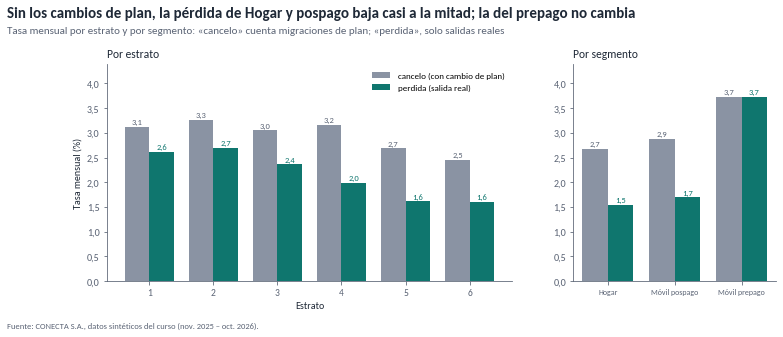

Cómo se va el que se va (% de las pérdidas de cada segmento):


tipo_cancelacion,Por mora,Sin recarga,Voluntaria
segmento,,,
Hogar,25.6,0.0,74.4
Móvil pospago,29.8,0.0,70.2
Móvil prepago,0.0,30.3,69.7


In [7]:
d["perdida"] = ((d["cancelo"] == 1) & (d["tipo_cancelacion"] != "Cambio de plan")).astype(int)
n_cambio = int((d["cancelo"] == 1).sum()) - int(d["perdida"].sum())
print(f"Filas que eran «cancelo» por un cambio de plan: {miles(n_cambio)}")
print(f"Tasa mensual: cancelo {decimal(100 * d['cancelo'].mean(), 1)} % → perdida "
      f"{decimal(100 * d['perdida'].mean(), 1)} % "
      f"({decimal(100 * n_cambio / d['cancelo'].sum(), 1)} % de las cancelaciones eran cambios de plan)")

d["segmento"] = np.where(d["linea"] == "Hogar", "Hogar",
                         np.where(d["modalidad"] == "Prepago", "Móvil prepago", "Móvil pospago"))
por_estrato = 100 * d.groupby("estrato")[["cancelo", "perdida"]].mean()
por_segmento = 100 * d.groupby("segmento")[["cancelo", "perdida"]].mean()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [2, 1]})
for ax, tabla, nombre in ((a1, por_estrato, "Por estrato"), (a2, por_segmento, "Por segmento")):
    x, w = np.arange(len(tabla)), 0.38
    ax.bar(x - w / 2, tabla["cancelo"], width=w, color=PALETA["neutro"], label="cancelo (con cambio de plan)")
    ax.bar(x + w / 2, tabla["perdida"], width=w, color=PALETA["principal"], label="perdida (salida real)")
    for xi, (c_, p_) in enumerate(zip(tabla["cancelo"], tabla["perdida"])):
        ax.text(xi - w / 2, c_ + 0.05, decimal(c_, 1), ha="center", fontsize=8.5, color=PALETA["secundario"])
        ax.text(xi + w / 2, p_ + 0.05, decimal(p_, 1), ha="center", fontsize=8.5, color=PALETA["principal"])
    ax.set_xticks(x); ax.set_xticklabels(tabla.index, fontsize=9.5)
    ax.set_ylim(0, 4.4); ax.set_title(nombre, loc="left", fontsize=11.5, color=PALETA["texto"])
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: decimal(v, 1)))
a1.set_xlabel("Estrato"); a1.set_ylabel("Tasa mensual (%)"); a1.legend(frameon=False, fontsize=9)
a2.set_xlabel(""); a2.tick_params(axis="x", labelsize=8)
titulo(fig, "Sin los cambios de plan, la pérdida de Hogar y pospago baja casi a la mitad; la del prepago no cambia",
       "Tasa mensual por estrato y por segmento: «cancelo» cuenta migraciones de plan; «perdida», solo salidas reales")
fuente(fig, FUENTE_CONECTA)
guardar(fig, "t3_cancelo_vs_perdida.png")
plt.show()

tipos = 100 * pd.crosstab(d.loc[d["perdida"] == 1, "segmento"],
                          d.loc[d["perdida"] == 1, "tipo_cancelacion"], normalize="index")
print("Cómo se va el que se va (% de las pérdidas de cada segmento):")
display(tipos.round(1))


In [8]:
ranking = d.groupby(["codigo_upz", "upz", "localidad"]).agg(clientes=("cliente_id", "nunique"),
                                                                cancelo=("cancelo", "mean"), perdida=("perdida", "mean"))
ranking = ranking[ranking["clientes"] >= 80].copy()
ranking["puesto_cancelo"] = ranking["cancelo"].rank(ascending=False, method="first").astype(int)
ranking["puesto_perdida"] = ranking["perdida"].rank(ascending=False, method="first").astype(int)
k = round(0.10 * len(ranking))
ranking["top_cancelo"] = ranking["puesto_cancelo"] <= k
ranking["top_perdida"] = ranking["puesto_perdida"] <= k
print(f"{len(ranking)} UPZ con al menos 80 clientes; el 10 % peor son k = {k}")

entran = ranking[ranking["top_perdida"] & ~ranking["top_cancelo"]]
salen = ranking[~ranking["top_perdida"] & ranking["top_cancelo"]]
print("Entran al 10 % peor solo con «perdida»:", ", ".join(entran.index.get_level_values("upz").str.title()))
print("Salen del 10 % peor con «perdida»:", ", ".join(salen.index.get_level_values("upz").str.title()))

esmeralda = ranking[ranking.index.get_level_values("upz").str.contains("ESMERALDA")]
p_c, p_p = int(esmeralda["puesto_cancelo"].iloc[0]), int(esmeralda["puesto_perdida"].iloc[0])
print(f"La Esmeralda: puesto {p_c} con «cancelo» → puesto {p_p} con «perdida» "
      f"(buena parte de sus «cancelaciones» eran cambios de plan: {decimal(100 * esmeralda['cancelo'].iloc[0], 2)} % "
      f"frente a {decimal(100 * esmeralda['perdida'].iloc[0], 2)} %)")

display(ranking[ranking["top_perdida"]].sort_values("perdida", ascending=False)
        .assign(cancelo=lambda t: (100 * t["cancelo"]).round(2), perdida=lambda t: (100 * t["perdida"]).round(2)))


95 UPZ con al menos 80 clientes; el 10 % peor son k = 10
Entran al 10 % peor solo con «perdida»: Sosiego, Los Libertadores, Bosa Occidental
Salen del 10 % peor con «perdida»: Los Andes, El Tesoro, Chapinero
La Esmeralda: puesto 32 con «cancelo» → puesto 77 con «perdida» (buena parte de sus «cancelaciones» eran cambios de plan: 3,20 % frente a 1,68 %)


,,,clientes,cancelo,perdida,puesto_cancelo,puesto_perdida,top_cancelo,top_perdida
codigo_upz,upz,localidad,,,,,,,
44,AMERICAS,KENNEDY,343,5.42,4.52,1,1,True,True
47,KENNEDY CENTRAL,KENNEDY,423,4.82,4.04,2,2,True,True
26,LAS FERIAS,ENGATIVA,524,4.69,4.02,4,3,True,True
31,SANTA CECILIA,ENGATIVA,403,4.70,3.81,3,4,True,True
113,BAVARIA,KENNEDY,274,4.12,3.65,6,5,True,True
19,EL PRADO,SUBA,563,4.58,3.64,5,6,True,True
51,LOS LIBERTADORES,SAN CRISTOBAL,177,3.63,3.27,13,7,False,True
50,LA GLORIA,SAN CRISTOBAL,181,3.79,3.26,10,8,True,True
84,BOSA OCCIDENTAL,BOSA,490,3.64,3.25,12,9,False,True


**Bitácora de la Tarea 3.** Una viñeta por regla: problema, decisión, por qué y cuántos registros afecta (la cifra que imprimió su código).

**Su respuesta:**

- **`cancelo` mezcla salidas con «cambio de plan» — se crea `perdida` (cancelación sin cambio de plan).** El cliente que cambia de plan sigue con CONECTA y no es objetivo de una campaña de retención. Afecta a **2 464** filas que cambian de definición.
- **Las UPZ con menos de 80 clientes quedan fuera del ranking** — con menos clientes la tasa es inestable (como el intervalo de Candelaria en la S2; criterio del curso). De 102 UPZ quedan **95** en el ranking.


**¿Qué cambia al contar solo las pérdidas: por estrato, por segmento y en el ranking de UPZ? ¿Por qué importa para la campaña?**

*Consulten en la presentación:* diapositiva 6, «La regla, cliente por cliente»; diapositiva 36, «Los segmentos de clientes» (sección «La bitácora»).

**Su respuesta:** Contando solo pérdidas la brecha por estrato se amplía (los estratos 5 y 6 bajan más: el cambio de plan se concentra en quienes pueden pagar planes mejores); por segmento, Hogar pasa de 2,7 % a 1,5 % y pospago de 2,9 % a 1,7 % — casi a la mitad — mientras el prepago queda igual (3,7 %, porque en prepago no hay «cambio de plan»: se va sin avisar, por mora o sin recarga). En el ranking, tres UPZ entran al 10 % peor solo con `perdida` (Sosiego, Los Libertadores, Bosa Occidental) y tres salen (Los Andes, El Tesoro, Chapinero); La Esmeralda cae del puesto 32 al 77 porque la mitad de sus «cancelaciones» eran cambios de plan. Importa porque la campaña apunta a quien se va de verdad: medir migraciones como churn inflaría Hogar y pospago y mandaría la campaña a las UPZ equivocadas.


## Tarea 4 — Datos faltantes: el NPS

El NPS falta en cerca del 79 % de las filas. Calculen el porcentaje de respuesta según las quejas del mes (0, 1, 2,
3 o más). Si faltara completamente al azar (MCAR), la respuesta sería pareja (van Buuren, 2018, §1.2). Registren en
la bitácora su decisión sobre el NPS.

El NPS falta en el 78,5 % de las filas (275 553 nulos)
Respuesta según quejas del mes: {0: '21,9 %', 1: '19,4 %', 2: '17,4 %', 3: '14,7 %'}


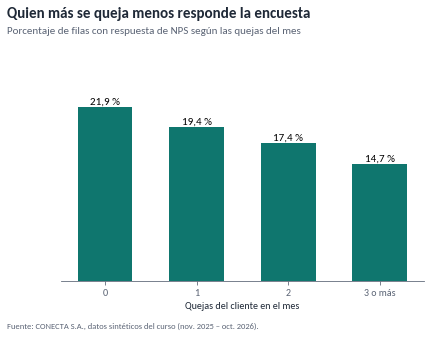

In [9]:
respuesta_nps = d.assign(responde=d["nps"].notna(), quejas=d["quejas_mes"].clip(upper=3))
respuesta_nps = 100 * respuesta_nps.groupby("quejas")["responde"].mean()
print(f"El NPS falta en el {decimal(100 * d['nps'].isna().mean(), 1)} % de las filas "
      f"({miles(int(d['nps'].isna().sum()))} nulos)")
print("Respuesta según quejas del mes:", {int(i): f"{decimal(v, 1)} %" for i, v in respuesta_nps.items()})

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.bar(["0", "1", "2", "3 o más"], respuesta_nps.values, color=PALETA["principal"], width=0.6)
for i, v in enumerate(respuesta_nps.values):
    ax.text(i, v + 0.4, f"{decimal(v, 1)} %", ha="center", fontsize=11)
ax.spines["left"].set_visible(False); ax.set_yticks([]); ax.set_ylim(0, respuesta_nps.max() * 1.25)
ax.set_xlabel("Quejas del cliente en el mes")
titulo(fig, "Quien más se queja menos responde la encuesta",
       "Porcentaje de filas con respuesta de NPS según las quejas del mes")
fuente(fig, FUENTE_CONECTA)
guardar(fig, "t4_respuesta_nps.png")
plt.show()


**¿El NPS falta al azar? ¿Qué deciden hacer con él y para qué puede servir todavía?**

*Consulten en la presentación:* diapositiva 23, «Datos faltantes: ¿de qué depende que un dato falte?» (sección «Los problemas del caso»); diapositiva 25, «Cómo saber cuál es» (sección «Los problemas del caso»); diapositiva 27, «QUÉ HACER CON LOS FALTANTES» (sección «Los problemas del caso»).

**Su respuesta:** No falta al azar: la respuesta baja del 21,9 % sin quejas al 14,7 % con 3 o más, así que depende al menos de las quejas, que sí observamos (MAR), y podría depender de la propia satisfacción (MNAR), lo que los datos no pueden mostrar. Decisión: se conserva la columna sin imputar nada — la tasa de cancelación no la usa, e imputarla asignaría a los que más se quejan la satisfacción de los que no. Para qué sirve todavía: la **falta misma es un dato** (no responder ya marca insatisfacción, y puede usarse como variable), y el promedio de quienes responden, reportado siempre con su sesgo, sobrestima la satisfacción.


**Bitácora de la Tarea 4.** Una viñeta por regla: problema, decisión, por qué y cuántos registros afecta (la cifra que imprimió su código).

**Su respuesta:**

- **`nps` falta en el 78,5 % de las filas y no al azar — se conserva sin imputar.** La respuesta baja con las quejas (21,9 % → 14,7 %), así que es al menos MAR; la tasa de cancelación no usa el NPS y el promedio de quienes responden sobrestima la satisfacción. La propia falta queda disponible como variable. Afecta a **275 553** filas con nulo.


## Tarea 5 — Tabla limpia y UPZ candidatas

1. Guarden `d` como `salidas/conecta_limpio_s3.csv`.
2. Las candidatas: la tasa de pérdida por UPZ (`tasa_pct`, en %) y el porcentaje de filas prepago (`pct_prepago`, en
   %), solo para las UPZ con al menos 80 clientes. Son el **10 % peor**: las `k = round(0,10 × n)` UPZ con la tasa más
   alta. Guárdenlas en `salidas/upz_candidatas_s3.csv`: son la entrada de la S4.

In [10]:
d = d.drop(columns="segmento").reset_index(drop=True)     # el segmento se calcula; no se guarda
d.to_csv(SALIDAS / "conecta_limpio_s3.csv", index=False, encoding="utf-8")
print(f"Tabla limpia guardada: {SALIDAS / 'conecta_limpio_s3.csv'} ({miles(len(d))} filas, {d.shape[1]} columnas)")


Tabla limpia guardada: salidas/conecta_limpio_s3.csv (351 127 filas, 20 columnas)


In [11]:
por_upz = d.groupby(["codigo_upz", "upz", "localidad"]).agg(clientes=("cliente_id", "nunique"),
                                                              tasa_pct=("perdida", lambda s: 100 * s.mean()),
                                                              pct_prepago=("modalidad", lambda s: 100 * (s == "Prepago").mean()))
por_upz = por_upz[por_upz["clientes"] >= 80]
k = round(0.10 * len(por_upz))
candidatas = por_upz.nlargest(k, "tasa_pct")
candidatas.reset_index().to_csv(SALIDAS / "upz_candidatas_s3.csv", index=False, encoding="utf-8")
print(f"{len(por_upz)} UPZ con al menos 80 clientes; las {k} con más pérdida quedan en "
      f"{SALIDAS / 'upz_candidatas_s3.csv'}")
display(candidatas.round(2))


95 UPZ con al menos 80 clientes; las 10 con más pérdida quedan en salidas/upz_candidatas_s3.csv


,,,clientes,tasa_pct,pct_prepago
codigo_upz,upz,localidad,,,
44,AMERICAS,KENNEDY,343,4.52,38.24
47,KENNEDY CENTRAL,KENNEDY,423,4.04,28.78
26,LAS FERIAS,ENGATIVA,524,4.02,27.42
31,SANTA CECILIA,ENGATIVA,403,3.81,30.40
113,BAVARIA,KENNEDY,274,3.65,30.74
19,EL PRADO,SUBA,563,3.64,24.87
51,LOS LIBERTADORES,SAN CRISTOBAL,177,3.27,68.83
50,LA GLORIA,SAN CRISTOBAL,181,3.26,60.45
84,BOSA OCCIDENTAL,BOSA,490,3.25,72.40


**¿Qué UPZ llevarían a la S4 como candidatas y qué deberían verificar antes de llevarlas al comité?**

*Consulten en la presentación:* diapositiva 36, «Los segmentos de clientes» (sección «La bitácora»).

**Su respuesta:** Las 10 candidatas son Américas (4,5 %), Kennedy Central (4,0 %), Las Ferias (4,0 %), Santa Cecilia (3,8 %), Bavaria (3,7 %) y El Prado (3,6 %), más Los Libertadores, La Gloria, Bosa Occidental y Sosiego (~3,2–3,3 %): seis en Kennedy, Engativá y Suba, y cuatro en San Cristóbal y Bosa donde el 60–72 % de las filas es prepago. Antes del comité habría que verificar que la tasa sea sostenida y no un pico de un mes (las tasas mensuales por UPZ), que el prepago sea el que de verdad se va (la correlación de la S2 es entre UPZ, no cliente por cliente) y el volumen de clientes que una campaña podría cubrir en cada una.


## Preguntas de interpretación

**1. ¿Qué regla de limpieza cambió más la conclusión del proyecto y por qué?**

**Su respuesta:** La que más cambió la conclusión fue **contar la pérdida y no la cancelación**: quitar los 2 464 «cambio de plan» baja la tasa de 3,1 % a 2,4 %, casi a la mitad en Hogar y pospago, y cambia tres de las diez UPZ candidatas (entran Sosiego, Los Libertadores y Bosa Occidental; salen Los Andes, El Tesoro y Chapinero — y La Esmeralda, que nunca fue candidata, cae del puesto 32 al 77). Después de ella, quitar las cuentas internas y los duplicados es lo que más pesa: eran casi 3 600 filas que no eran clientes. Las normalizaciones (localidad, plan, coordenadas) no movieron la tasa pero hacen confiable el «dónde».


## Interpretación final para el negocio

Para la Gerencia de Retención, en 5–8 viñetas: qué problemas tenían los datos; qué se corrigió y qué no; cuánto
cambió la tasa frente a la de la S2; qué cambió del párrafo «Lo que llevamos a la S4» de la S2; qué UPZ pasan a la S4;
uso de IA.

**Su respuesta:**

- **Los datos tenían problemas de las cuatro categorías:** representación (38 grafías de localidad, 6 de plan, coordenadas intercambiadas), exactitud (1 765 duplicados, coordenadas en columnas cambiadas), completitud (5 264 coordenadas nulas, NPS al 78,5 % de faltantes) y contexto (una cuenta de prueba y 150 cuentas internas con pago 0 todo el año que no son clientes).
- **Se corrigió:** duplicados, prueba y cuentas internas fuera (quedan 351 127 filas de clientes); localidad y plan normalizados a los nombres oficiales; 1 039 coordenadas des-intercambiadas. **No se tocó:** las coordenadas nulas (la tasa no las usa e imputarlas inventaría ubicaciones) y el NPS (no es MCAR e imputar sesgaría; su falta misma queda como dato).
- **La tasa cambió de fondo:** de ~3,1 % con `cancelo` en el crudo a **2,4 %** con `perdida` en la tabla limpia — el «cambio de plan» (22,6 % de las cancelaciones) era migración, no churn. En Hogar y pospago la pérdida queda casi a la mitad; en prepago no cambia (allí se va sin avisar: 30 % sin recarga).
- **Qué cambió del párrafo «Lo que llevamos a la S4» de la S2:** el «dónde» ya no es provisional (los nombres están limpios y San Cristóbal/Bosa entran por UPZ, no solo por localidad); la magnitud del churn real es menor de lo que parecía, sobre todo en Hogar; y el prepago confirma su rol: concentra la pérdida real en las UPZ candidatas del sur.
- **UPZ que pasan a la S4:** Américas, Kennedy Central, Las Ferias, Santa Cecilia, Bavaria, El Prado, Los Libertadores, La Gloria, Bosa Occidental y Sosiego (tasa de pérdida 3,2–4,5 %; las de San Cristóbal y Bosa con 60–72 % de filas prepago).
- **Uso de IA:** el notebook se resolvió con un asistente y se revisó de forma adversarial, comprobando cada cifra y afirmación contra el insumo de datos.
